In [1]:
import numpy as np
import matplotlib.pyplot as plt
import hdbscan

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score

iris = load_iris()

X = StandardScaler().fit_transform(iris.data)
y = iris.target

print("Dataset Shape:", X.shape)
print("Original Classes:", iris.target_names)

Dataset Shape: (150, 4)
Original Classes: ['setosa' 'versicolor' 'virginica']


In [2]:
hdb = hdbscan.HDBSCAN(
    min_cluster_size=5,
    min_samples=5
)

labels = hdb.fit_predict(X)

n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = np.sum(labels == -1)

print("Number of Clusters:", n_clusters)
print("Amount of Noise:", n_noise)
print("Noise Percentage:", round(n_noise / len(X) * 100, 2), "%")
print("Adjusted Rand Index:", adjusted_rand_score(y, labels))

Number of Clusters: 2
Amount of Noise: 2
Noise Percentage: 1.33 %
Adjusted Rand Index: 0.539408633653917


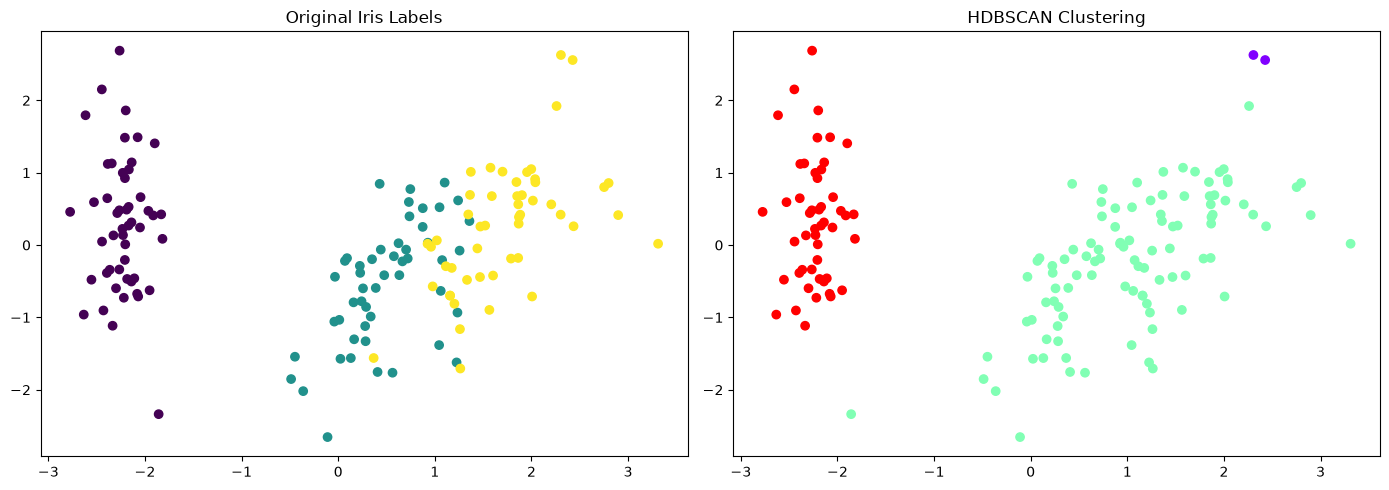

In [3]:
X_pca = PCA(n_components=2).fit_transform(X)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap='viridis')
axes[0].set_title("Original Iris Labels")

axes[1].scatter(X_pca[:, 0], X_pca[:, 1], c=labels, cmap='rainbow')
axes[1].set_title("HDBSCAN Clustering")

plt.tight_layout()
plt.show()

The Iris dataset was clustered using HDBSCAN with min_cluster_size=5 and min_samples=5. PCA was used to reduce the four-dimensional dataset into two dimensions for visualization.

The clustering results were compared with the original Iris labels using the Adjusted Rand Index (ARI). ARI measures the similarity between the clustering results and the original classes, where a value closer to 1 indicates better agreement.

HDBSCAN may classify some observations as noise (-1) and may not identify exactly three clusters because it determines clusters based on data density rather than predefined class labels.